# DATA ANALYSIS

## PART A

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from scipy.stats import boxcox
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

## 2. Load Data

In [2]:
df_train_FD001 = pd.read_csv("train_FD001.csv")
df_train_FD002 = pd.read_csv("train_FD002.csv")
df_test_FD001 = pd.read_csv("test_FD001.csv")
df_test_FD002 = pd.read_csv("test_FD002.csv")
df_rul_FD001 = pd.read_csv("RUL_FD001.csv")
df_rul_FD002 = pd.read_csv("RUL_FD002.csv")

## 3. Create a dictionary for easy data traversal

In [3]:
datasets = {
    "train_FD001": df_train_FD001,
    "train_FD002": df_train_FD002,
    "test_FD001": df_test_FD001,
    "test_FD002": df_test_FD002,
    "RUL_FD001": df_rul_FD001,
    "RUL_FD002": df_rul_FD002,
}

## 4. Analyze shape, columns, head, null values, and duplicate values

In [4]:
for name, df in datasets.items():
    print("=" * 90)
    print(name)
    print("shape:", df.shape)
    print("columns:", list(df.columns)[:10], "...")
    print(df.head(3))
    print("\nmissing values total:", df.isna().sum().sum())
    print("duplicate rows:", df.duplicated().sum())

train_FD001
shape: (20631, 26)
columns: ['unit_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5'] ...
   unit_id  cycle  setting_1  setting_2  setting_3  sensor_1  sensor_2  \
0        1      1    -0.0007    -0.0004      100.0    518.67    641.82   
1        1      2     0.0019    -0.0003      100.0    518.67    642.15   
2        1      3    -0.0043     0.0003      100.0    518.67    642.35   

   sensor_3  sensor_4  sensor_5  ...  sensor_12  sensor_13  sensor_14  \
0   1589.70   1400.60     14.62  ...     521.66    2388.02    8138.62   
1   1591.82   1403.14     14.62  ...     522.28    2388.07    8131.49   
2   1587.99   1404.20     14.62  ...     522.42    2388.03    8133.23   

   sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  sensor_20  sensor_21  
0     8.4195       0.03        392       2388      100.0      39.06    23.4190  
1     8.4318       0.03        392       2388      100.0      39.00    23.4236  
2  

### Inference: The data do not have missing or duplicate values except for RUL's data with duplicate values because different engines can have the same RUL

## 5. Statistical Description

In [5]:
for name, df in datasets.items():
    print("=" * 90)
    print(name)
    if "unit_id" in df.columns:
        print("number of units:", df["unit_id"].nunique())
        print("cycle min/max:", df["cycle"].min(), df["cycle"].max())
        
        unit_cycles = df.groupby("unit_id")["cycle"].agg(["count", "min", "max"])
        print("\nPer-unit cycle summary:")
        print(unit_cycles.describe())
        
        # Check cycles start at 1 and are contiguous
        bad_units = unit_cycles[
            (unit_cycles["min"] != 1) |
            (unit_cycles["count"] != unit_cycles["max"])
        ]
        print("\nUnits with non-contiguous cycles or not starting at 1:", len(bad_units))
        if len(bad_units) > 0:
            print(bad_units.head())
    
    if name.startswith("RUL"):
        print("RUL length:", len(df))
        print(df.head())

train_FD001
number of units: 100
cycle min/max: 1 362

Per-unit cycle summary:
            count    min         max
count  100.000000  100.0  100.000000
mean   206.310000    1.0  206.310000
std     46.342749    0.0   46.342749
min    128.000000    1.0  128.000000
25%    177.000000    1.0  177.000000
50%    199.000000    1.0  199.000000
75%    229.250000    1.0  229.250000
max    362.000000    1.0  362.000000

Units with non-contiguous cycles or not starting at 1: 0
train_FD002
number of units: 260
cycle min/max: 1 378

Per-unit cycle summary:
            count    min         max
count  260.000000  260.0  260.000000
mean   206.765385    1.0  206.765385
std     46.782198    0.0   46.782198
min    128.000000    1.0  128.000000
25%    174.000000    1.0  174.000000
50%    199.000000    1.0  199.000000
75%    230.250000    1.0  230.250000
max    378.000000    1.0  378.000000

Units with non-contiguous cycles or not starting at 1: 0
test_FD001
number of units: 100
cycle min/max: 1 303

Per-un

### Inference:...

## 6. Alignment Check

In [26]:
# Check RUL alignment
print("\n" + "=" * 90)
print("RUL alignment check")
print("FD001 train units:", df_train_FD001["unit_id"].nunique(), "| test units:", df_test_FD001["unit_id"].nunique(), "| RUL rows:", len(df_rul_FD001))
print("FD002 train units:", df_train_FD002["unit_id"].nunique(), "| test units:", df_test_FD002["unit_id"].nunique(), "| RUL rows:", len(df_rul_FD002))


RUL alignment check
FD001 train units: 100 | test units: 100 | RUL rows: 100
FD002 train units: 260 | test units: 259 | RUL rows: 259


## Inference: Data aligned correctly

## 7. Constant / Near Constant Columns

In [27]:
# Constant / near-constant columns in train sets
for name, df in [("train_FD001", df_train_FD001), ("train_FD002", df_train_FD002)]:
    nunique = df.nunique()
    constant_cols = nunique[nunique <= 1].index.tolist()
    print("\n" + "=" * 90)
    print(name)
    print("Constant columns:", constant_cols)
    print("\nColumn nunique values:")
    print(nunique.sort_values().head(30))


train_FD001
Constant columns: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

Column nunique values:
sensor_1        1
setting_3       1
sensor_10       1
sensor_5        1
sensor_19       1
sensor_16       1
sensor_18       1
sensor_6        2
sensor_17      13
setting_2      13
sensor_8       53
sensor_13      56
unit_id       100
sensor_20     120
setting_1     158
sensor_11     159
sensor_2      310
cycle         362
sensor_12     427
sensor_7      513
sensor_15    1918
sensor_3     3012
sensor_4     4051
sensor_21    4745
sensor_14    6078
sensor_9     6403
dtype: int64

train_FD002
Constant columns: []

Column nunique values:
setting_3        2
sensor_19        2
sensor_16        2
sensor_1         6
sensor_5         6
sensor_18        6
sensor_10        9
sensor_6        14
sensor_17       53
setting_2      105
unit_id        260
cycle          378
sensor_20      510
sensor_13      514
setting_1      536
sensor_11      681
sensor_8    

### Inference: train_FD001 Constant columns: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
### Inference: train_FD002 Near Constant Columns: ['setting_3', 'sensor_19', 'sensor_16', 'sensor_1', 'sensor_5', 'sensor_18', 'sensor_10']

## 8. Statistical Analysis

In [28]:
# Summary statistics for sensors and settings
for name, df in [("train_FD001", df_train_FD001), ("train_FD002", df_train_FD002)]:
    print("\n" + "=" * 90)
    print(name, "summary stats")
    print(df.describe().T)


train_FD001 summary stats
             count         mean           std        min        25%  \
unit_id    20631.0    51.506568  2.922763e+01     1.0000    26.0000   
cycle      20631.0   108.807862  6.888099e+01     1.0000    52.0000   
setting_1  20631.0    -0.000009  2.187313e-03    -0.0087    -0.0015   
setting_2  20631.0     0.000002  2.930621e-04    -0.0006    -0.0002   
setting_3  20631.0   100.000000  0.000000e+00   100.0000   100.0000   
sensor_1   20631.0   518.670000  0.000000e+00   518.6700   518.6700   
sensor_2   20631.0   642.680934  5.000533e-01   641.2100   642.3250   
sensor_3   20631.0  1590.523119  6.131150e+00  1571.0400  1586.2600   
sensor_4   20631.0  1408.933782  9.000605e+00  1382.2500  1402.3600   
sensor_5   20631.0    14.620000  5.329200e-15    14.6200    14.6200   
sensor_6   20631.0    21.609803  1.388985e-03    21.6000    21.6100   
sensor_7   20631.0   553.367711  8.850923e-01   549.8500   552.8100   
sensor_8   20631.0  2388.096652  7.098548e-02  238

### Inference:...

## PART B

## 1. Add RUL to Training Sets

In [29]:
def add_rul(df):
    df = df.copy()
    max_cycle = df.groupby('unit_id')['cycle'].transform('max')
    df['RUL'] = max_cycle - df['cycle']
    return df

train1 = add_rul(df_train_FD001)
train2 = add_rul(df_train_FD002)

print("Train FD001 with RUL (head):")
print(train1[['unit_id', 'cycle', 'RUL']].head())
print("\nTrain FD002 with RUL (head):")
print(train2[['unit_id', 'cycle', 'RUL']].head())

Train FD001 with RUL (head):
   unit_id  cycle  RUL
0        1      1  191
1        1      2  190
2        1      3  189
3        1      4  188
4        1      5  187

Train FD002 with RUL (head):
   unit_id  cycle  RUL
0        1      1  148
1        1      2  147
2        1      3  146
3        1      4  145
4        1      5  144


## 2. Correlation of each sensor/setting with RUL

In [30]:
def sensor_rul_corr(df, name):
    # Drop unit_id and cycle, keep RUL for correlation
    corr = df.drop(columns=['unit_id', 'cycle']).corr()['RUL'].drop('RUL').sort_values()
    print(f"\n{name} - Correlation with RUL (sorted):")
    print(corr)

sensor_rul_corr(train1, "FD001")
sensor_rul_corr(train2, "FD002")


FD001 - Correlation with RUL (sorted):
sensor_11   -0.696228
sensor_4    -0.678948
sensor_15   -0.642667
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
setting_1   -0.003198
setting_2   -0.001948
sensor_20    0.629428
sensor_21    0.635662
sensor_7     0.657223
sensor_12    0.671983
setting_3         NaN
sensor_1          NaN
sensor_5          NaN
sensor_10         NaN
sensor_16         NaN
sensor_18         NaN
sensor_19         NaN
Name: RUL, dtype: float64

FD002 - Correlation with RUL (sorted):
sensor_16   -0.071352
sensor_11   -0.046950
sensor_14   -0.042325
sensor_4    -0.040978
sensor_15   -0.038455
sensor_17   -0.027031
sensor_3    -0.026942
sensor_9    -0.015306
sensor_2    -0.004928
sensor_5    -0.000758
sensor_6    -0.000496
sensor_1    -0.000023
setting_2    0.000047
setting_1    0.001135
sensor_12    0.002249
sensor_7     0.002430
sensor_10    0

### Inference: FD001 - some sensors/settings with above 0.5 |correlation|
### Inference: FD002 - very weak correlation maybe due to 6 operating conditions

## 3. Sensor Trajectories for a few units

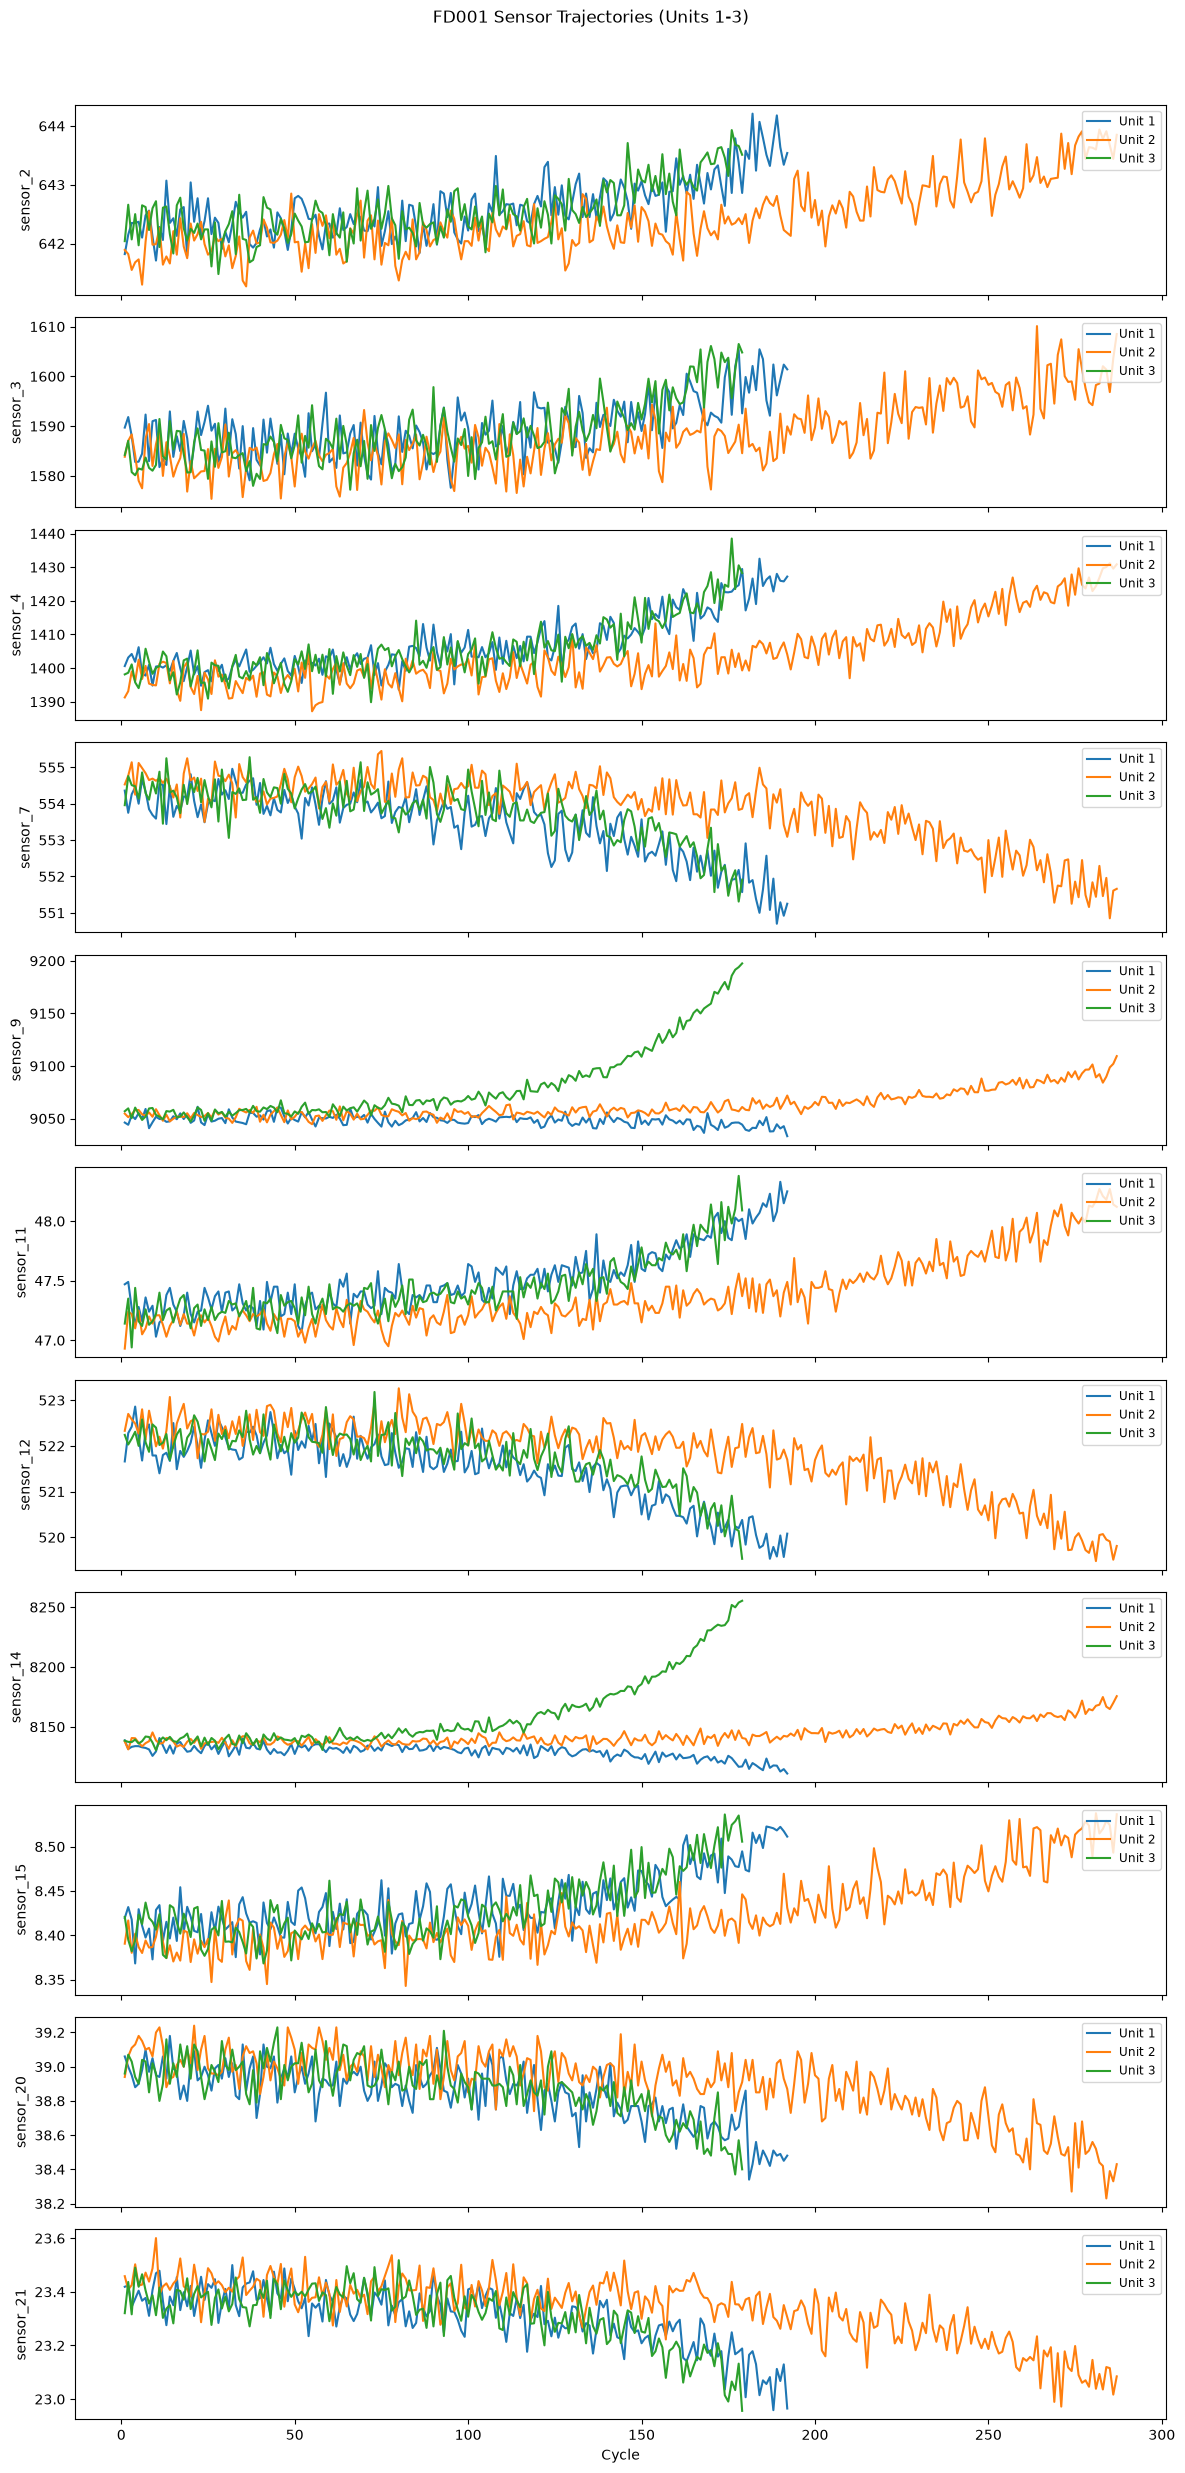

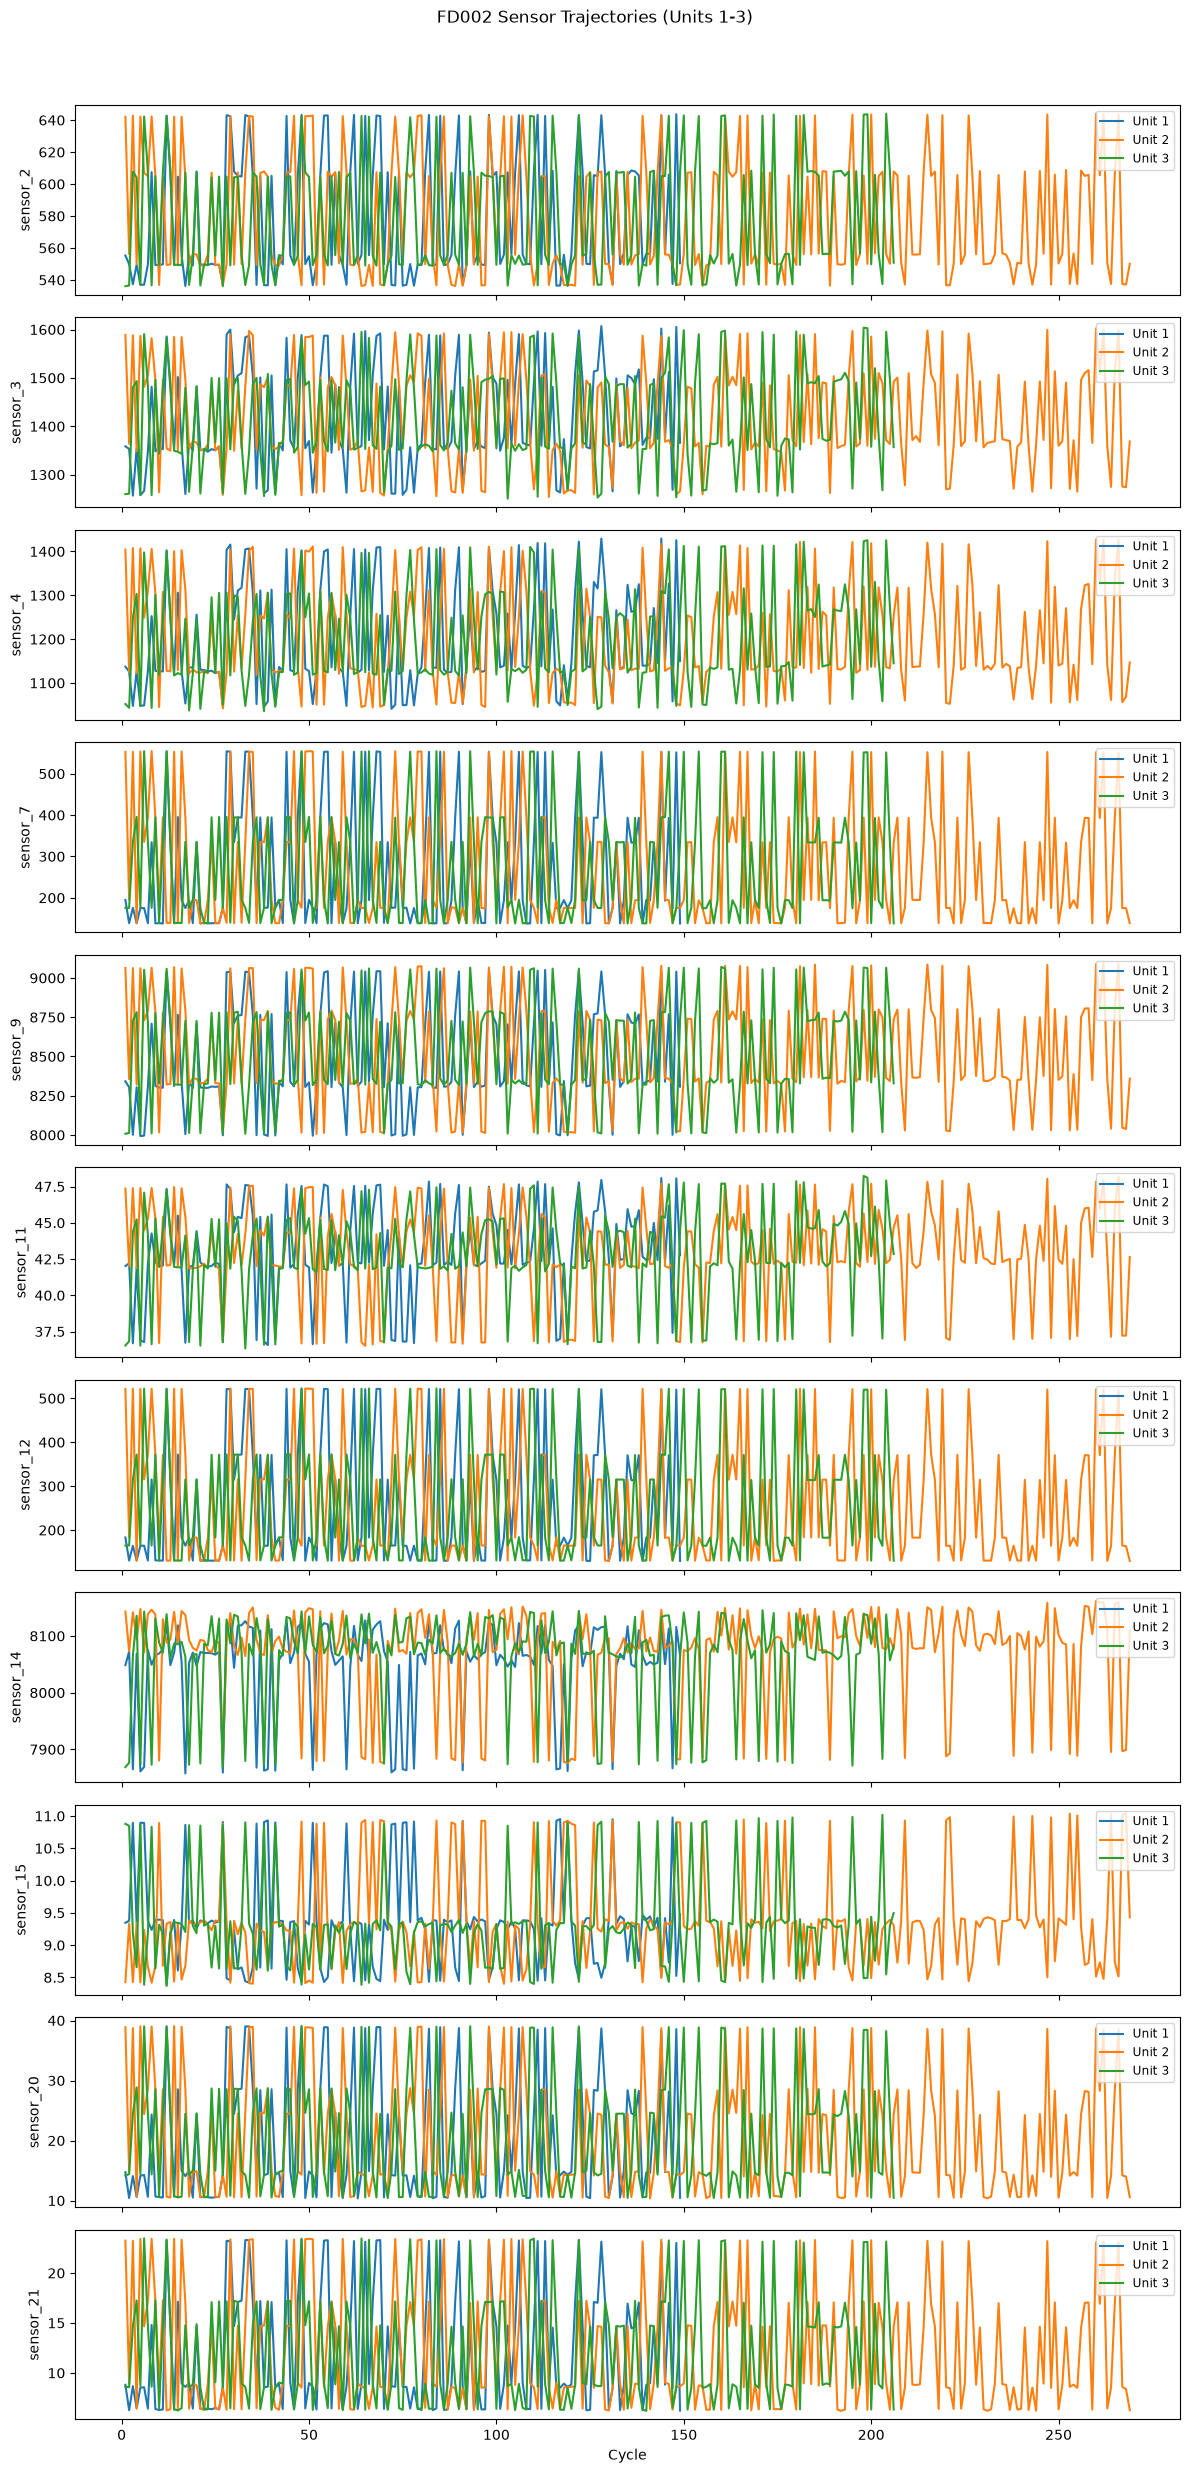

In [31]:
# We'll pick a few sensors that are not constant/near-constant.
# For FD001, constant sensors: sensor_1,5,10,16,18,19; near-constant: sensor_6,8,13,17.
# So we plot: sensor_2, sensor_3, sensor_4, sensor_7, sensor_9, sensor_11, sensor_12, sensor_14, sensor_15, sensor_20, sensor_21.
# For FD002, we plot the same set for comparison.

sensors_to_plot = ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_14', 'sensor_15', 'sensor_20', 'sensor_21']

def plot_sensors(df, unit_ids, sensors, title):
    fig, axes = plt.subplots(len(sensors), 1, figsize=(12, 2.2 * len(sensors)), sharex=True)
    for i, sensor in enumerate(sensors):
        for uid in unit_ids:
            unit_data = df[df['unit_id'] == uid]
            axes[i].plot(unit_data['cycle'], unit_data[sensor], label=f'Unit {uid}')
        axes[i].set_ylabel(sensor)
        axes[i].legend(loc='upper right', fontsize='small')
    axes[-1].set_xlabel('Cycle')
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()

# Plot for first 3 units of FD001 and FD002
plot_sensors(train1, [1, 2, 3], sensors_to_plot, 'FD001 Sensor Trajectories (Units 1-3)')
plot_sensors(train2, [1, 2, 3], sensors_to_plot, 'FD002 Sensor Trajectories (Units 1-3)')

### Inference:...

## 4. Averaged sensor trajectory over normalized life

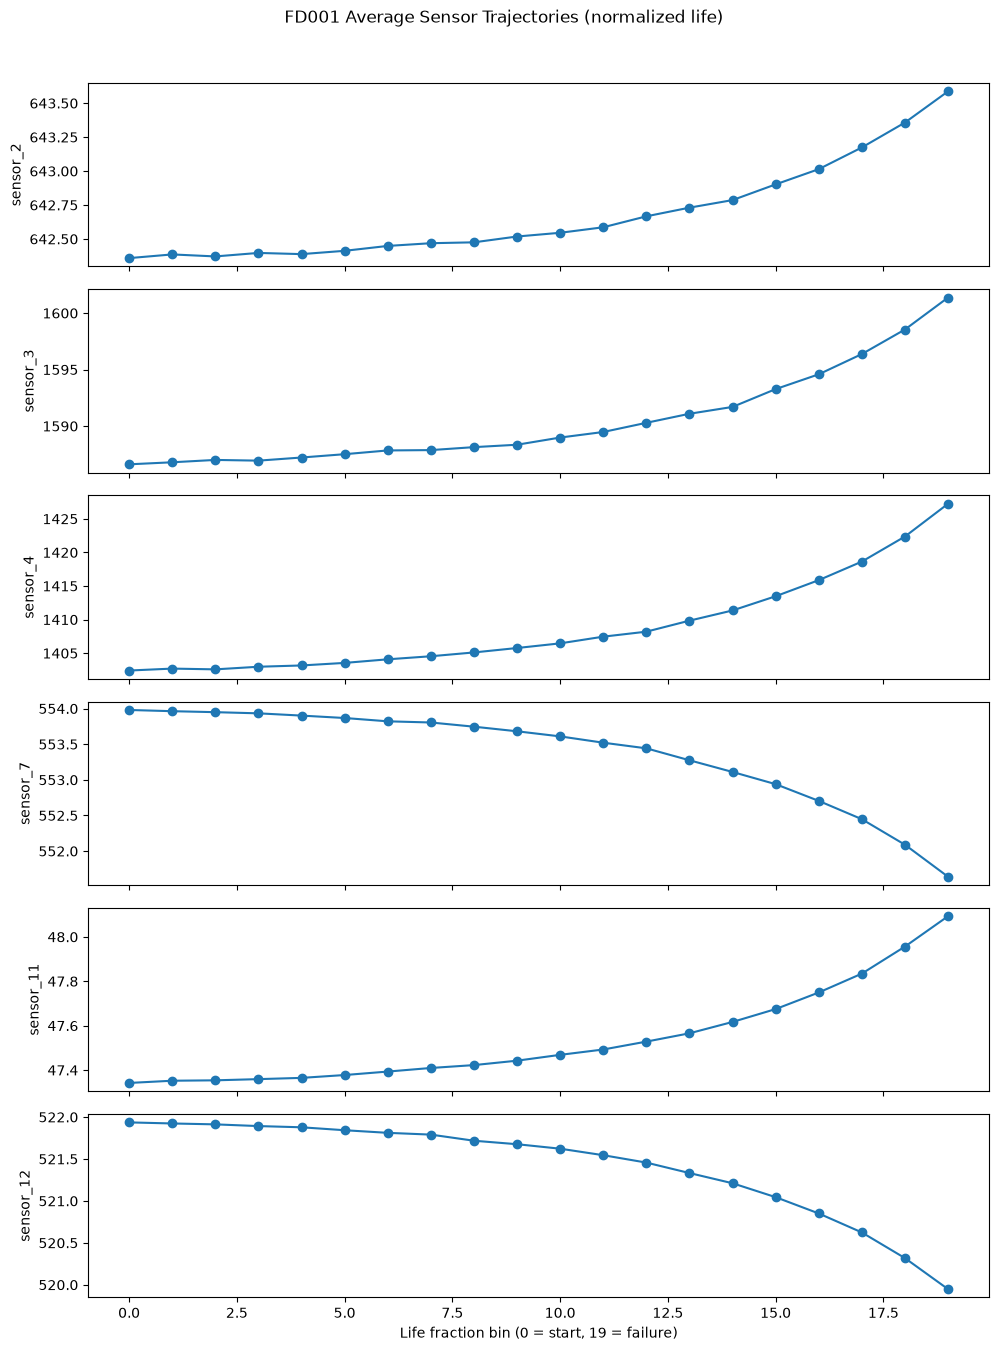

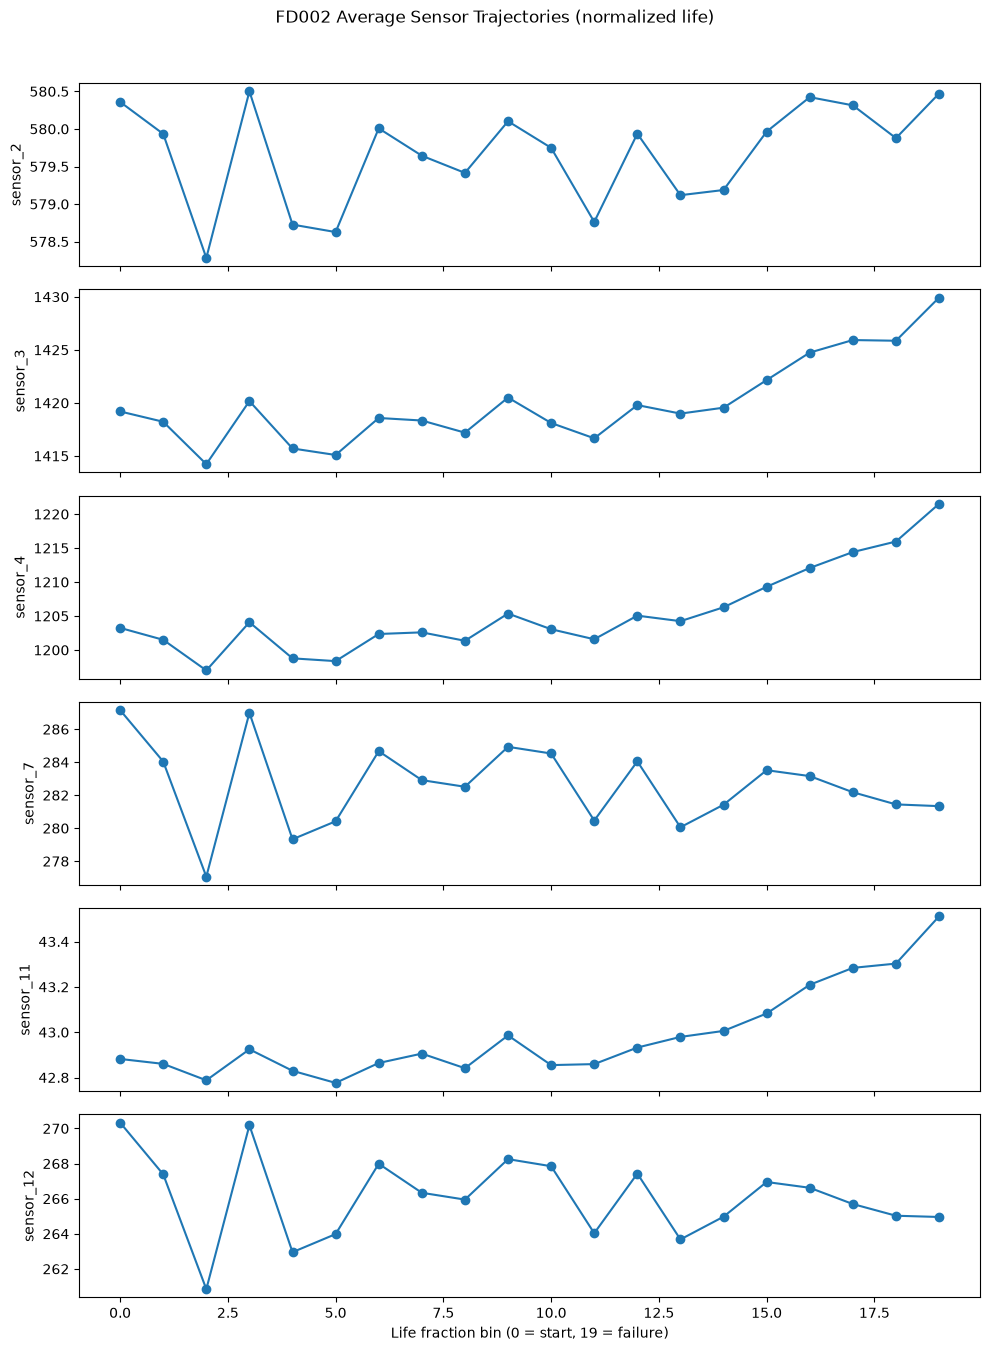

In [32]:
def plot_avg_trajectory(df, sensors, title):
    df = df.copy()
    # Normalize cycle: fraction of life (0 = start, 1 = failure)
    max_cycle = df.groupby('unit_id')['cycle'].transform('max')
    df['life_frac'] = df['cycle'] / max_cycle
    # Bin into 20 equal bins
    df['bin'] = pd.cut(df['life_frac'], bins=20, labels=False)
    avg = df.groupby('bin')[sensors].mean()
    fig, axes = plt.subplots(len(sensors), 1, figsize=(10, 2.2 * len(sensors)), sharex=True)
    for i, sensor in enumerate(sensors):
        axes[i].plot(avg.index, avg[sensor], marker='o')
        axes[i].set_ylabel(sensor)
    axes[-1].set_xlabel('Life fraction bin (0 = start, 19 = failure)')
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()

    # Use a subset of sensors for clarity (choose 6 with likely trends)
sensors_avg = ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_11', 'sensor_12']
plot_avg_trajectory(train1, sensors_avg, 'FD001 Average Sensor Trajectories (normalized life)')
plot_avg_trajectory(train2, sensors_avg, 'FD002 Average Sensor Trajectories (normalized life)')

### Inference:...

## PART C

## 1. FD001 curated sensors

In [33]:
FD001_SENSORS = [
    'sensor_2','sensor_3','sensor_4','sensor_7','sensor_8','sensor_9',
    'sensor_11','sensor_12','sensor_13','sensor_14','sensor_15',
    'sensor_17','sensor_20','sensor_21'
]

# Ensure RUL exists
def add_rul(df):
    df = df.copy()
    max_cycle = df.groupby('unit_id')['cycle'].transform('max')
    df['RUL'] = max_cycle - df['cycle']
    return df

train1 = add_rul(df_train_FD001)

# Pick top 3 by |corr| with RUL
corr1 = train1[FD001_SENSORS + ['RUL']].corr()['RUL'].drop('RUL')
top3_fd001 = corr1.abs().sort_values(ascending=False).head(3).index.tolist()
print("FD001 top 3 sensors by |corr| with RUL:", top3_fd001)
print(corr1.sort_values())

FD001 top 3 sensors by |corr| with RUL: ['sensor_11', 'sensor_4', 'sensor_12']
sensor_11   -0.696228
sensor_4    -0.678948
sensor_15   -0.642667
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_20    0.629428
sensor_21    0.635662
sensor_7     0.657223
sensor_12    0.671983
Name: RUL, dtype: float64


## 2. Analyze on multiple units (1, 5, 10) to check consistency

In [34]:
def analyze_series(series, label):
    series = np.asarray(series, dtype=float)
    out = {}
    # ADF
    adf = adfuller(series, autolag='AIC')
    out['adf_p'] = adf[1]
    # KPSS
    kp = kpss(series, regression='c', nlags='auto')
    out['kpss_p'] = kp[1]
    # Box-Cox
    if np.all(series > 0):
        _, lam = boxcox(series)
        out['boxcox_lambda'] = lam
    else:
        out['boxcox_lambda'] = None
    # First diff ADF
    if len(series) > 2:
        adf_d = adfuller(np.diff(series), autolag='AIC')
        out['adf_diff_p'] = adf_d[1]
    else:
        out['adf_diff_p'] = None
    print(f"\n--- {label} ---")
    print(f"ADF p={out['adf_p']:.4f}  |  KPSS p={out['kpss_p']:.4f}  "
          f"|  Box-Cox λ={out['boxcox_lambda']}  |  ADF(diff) p={out['adf_diff_p']:.4f}")
    return out

# Run on units 1, 5, 10 for each top sensor
for sensor in top3_fd001:
    for uid in [1, 5, 10]:
        s = train1.loc[train1['unit_id'] == uid, sensor].values
        analyze_series(s, f"FD001 {sensor} unit {uid}")

C:\Users\Anesu\AppData\Local\Temp\ipykernel_28232\2277976014.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(series, autolag='AIC')
C:\Users\Anesu\AppData\Local\Temp\ipykernel_28232\2277976014.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kp = kpss(series, regression='c', nlags='auto')
C:\Users\Anesu\AppData\Local\Temp\ipykernel_28232\2277976014.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July


--- FD001 sensor_11 unit 1 ---
ADF p=0.9990  |  KPSS p=0.0100  |  Box-Cox λ=-62.48211677277592  |  ADF(diff) p=0.0000

--- FD001 sensor_11 unit 5 ---
ADF p=1.0000  |  KPSS p=0.0100  |  Box-Cox λ=-76.27147359569881  |  ADF(diff) p=0.0000

--- FD001 sensor_11 unit 10 ---
ADF p=0.9971  |  KPSS p=0.0100  |  Box-Cox λ=-75.5509302994412  |  ADF(diff) p=0.0000

--- FD001 sensor_4 unit 1 ---
ADF p=0.9903  |  KPSS p=0.0100  |  Box-Cox λ=-73.07635856536331  |  ADF(diff) p=0.0000

--- FD001 sensor_4 unit 5 ---
ADF p=0.9989  |  KPSS p=0.0100  |  Box-Cox λ=-58.39461863647403  |  ADF(diff) p=0.0000

--- FD001 sensor_4 unit 10 ---
ADF p=0.9989  |  KPSS p=0.0100  |  Box-Cox λ=-59.68694031399143  |  ADF(diff) p=0.0000

--- FD001 sensor_12 unit 1 ---
ADF p=0.9932  |  KPSS p=0.0100  |  Box-Cox λ=112.67959235466915  |  ADF(diff) p=0.0000

--- FD001 sensor_12 unit 5 ---
ADF p=1.0000  |  KPSS p=0.0100  |  Box-Cox λ=112.67338762037434  |  ADF(diff) p=0.0000

--- FD001 sensor_12 unit 10 ---
ADF p=0.9989  |  

C:\Users\Anesu\AppData\Local\Programs\Python\Python314\Lib\site-packages\scipy\stats\_morestats.py:1237: UserWarning: The optimal lambda is 307.26800141320587, but the returned lambda is the constrained optimum to ensure that the maximum or the minimum of the transformed data does not overflow in float64.
  lmax = boxcox_normmax(x, method='mle', optimizer=optimizer, nan_policy=nan_policy)
C:\Users\Anesu\AppData\Local\Temp\ipykernel_28232\2277976014.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_d = adfuller(np.diff(series), autolag='AIC')
C:\Users\Anesu\AppData\Local\Temp\ipykernel_28232\2277976014.py:5: FutureWarning: adfuller currently returns a plain tuple whose len

## 3. ACF / PACF / Decomposition for unit 1 only (representative)

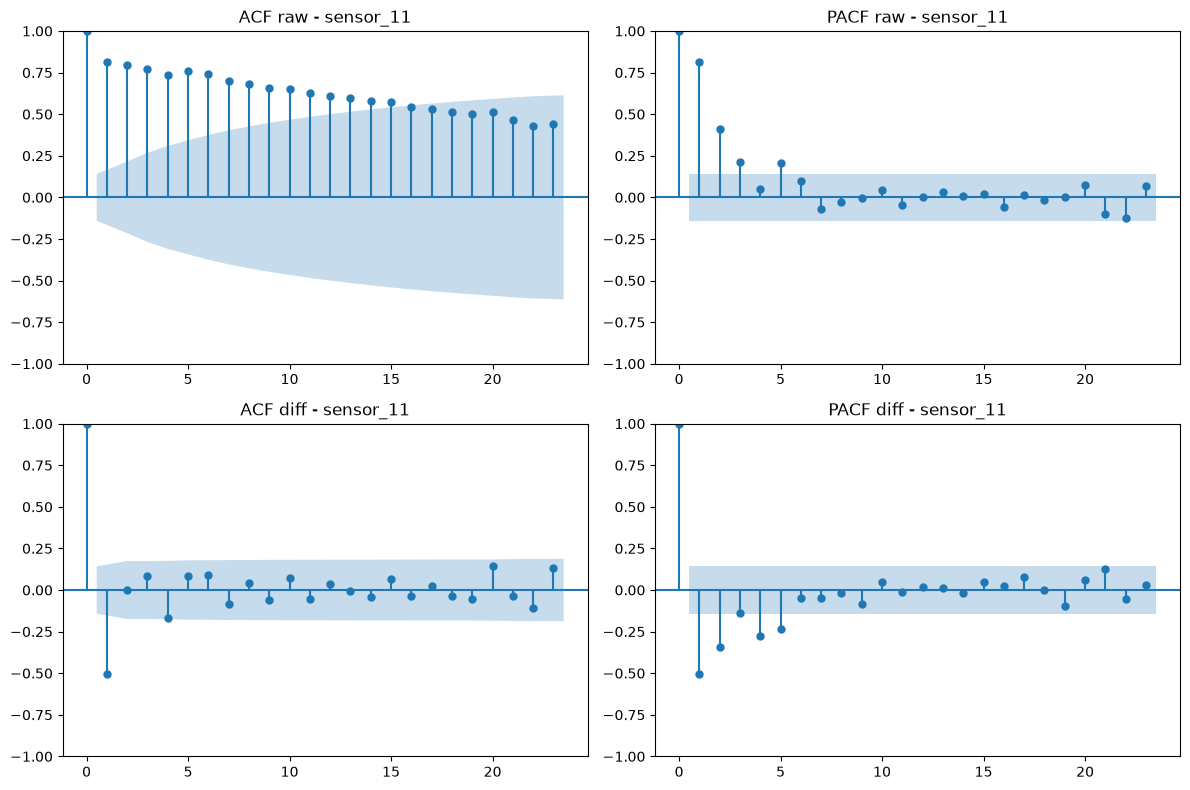

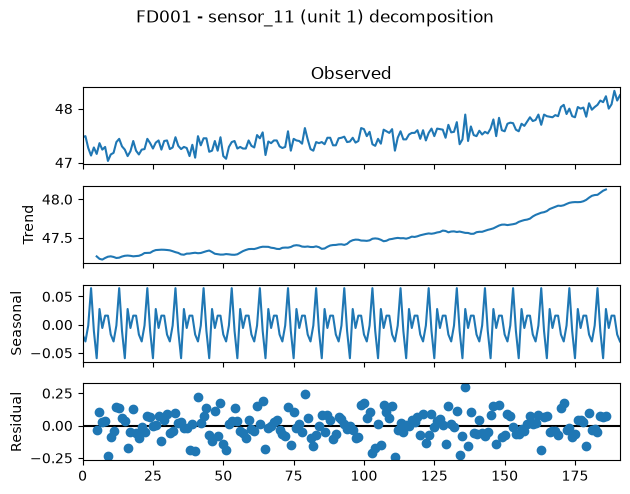

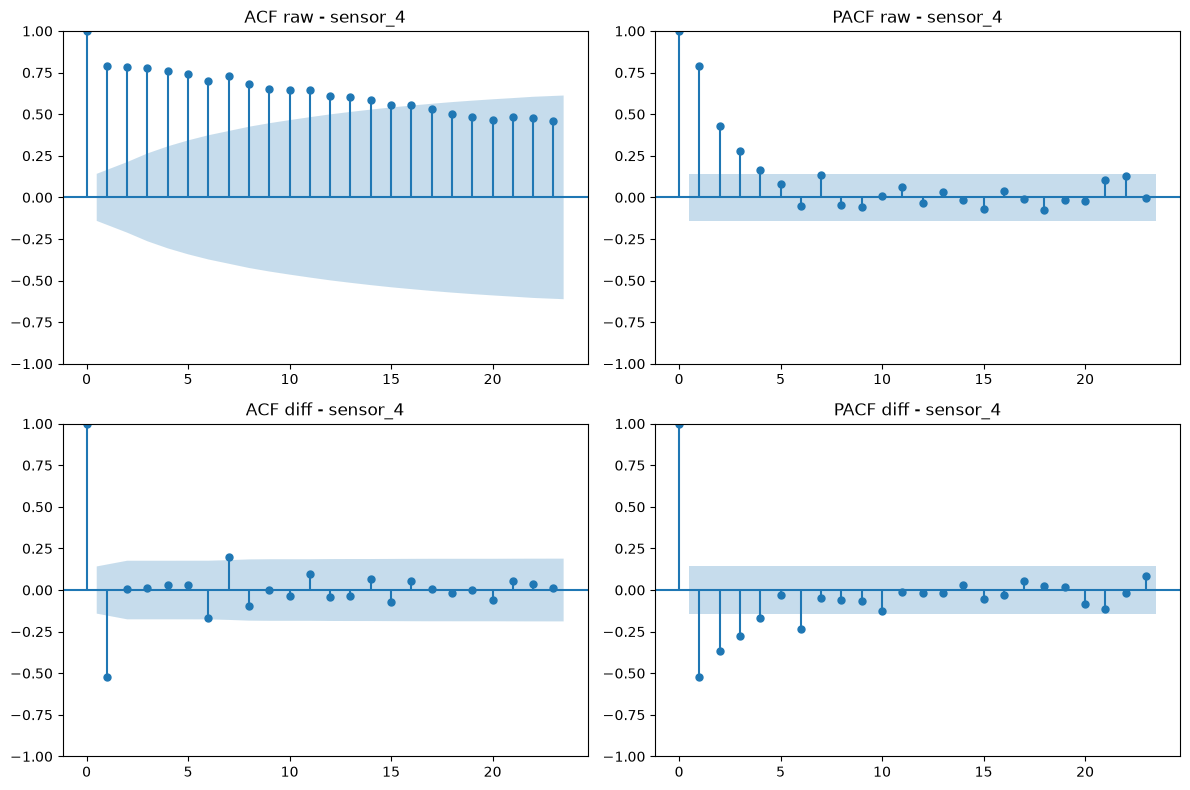

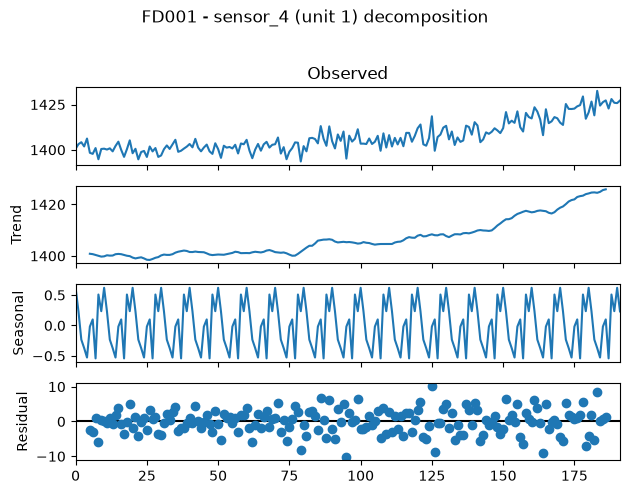

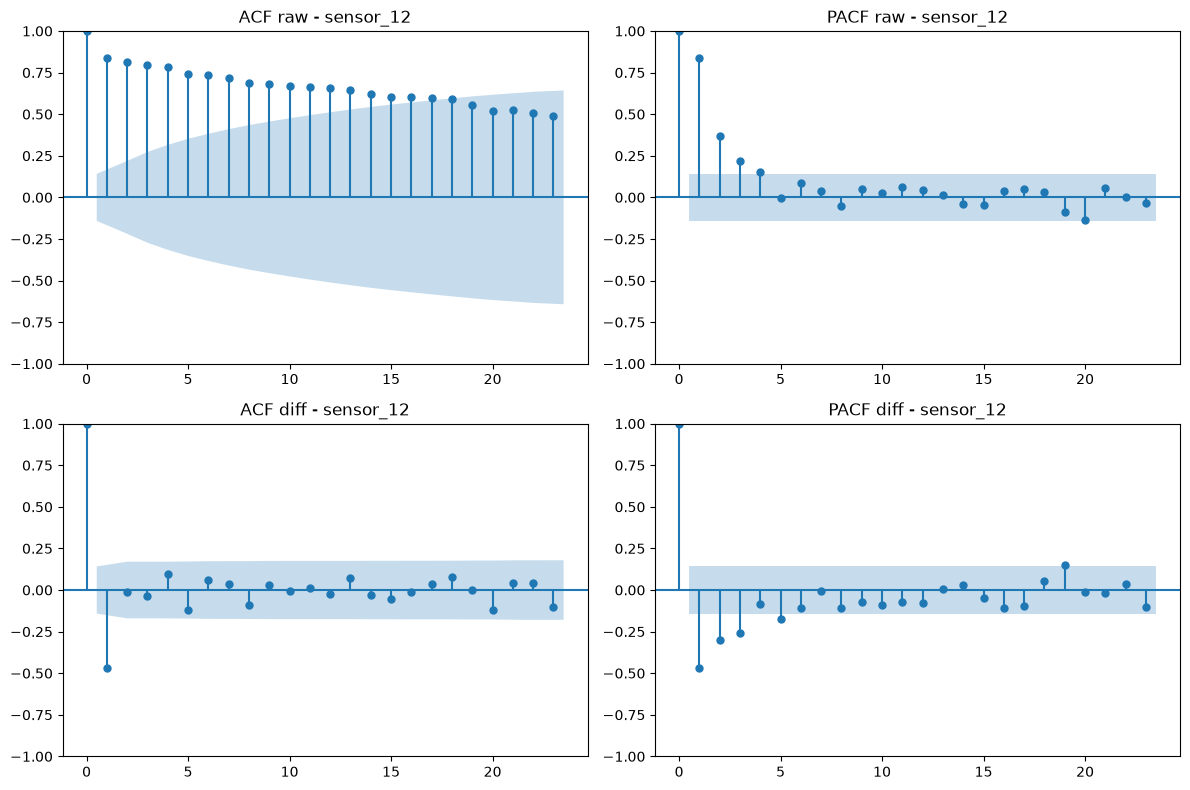

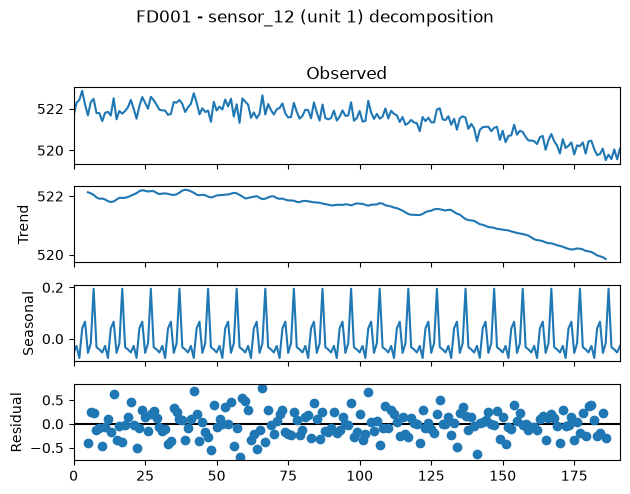

In [35]:
unit = train1[train1['unit_id'] == 1].sort_values('cycle')

for sensor in top3_fd001:
    series = unit[sensor].values.astype(float)
    diff = np.diff(series)

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    plot_acf(series, ax=axes[0,0], title=f'ACF raw - {sensor}')
    plot_pacf(series, ax=axes[0,1], title=f'PACF raw - {sensor}')
    plot_acf(diff, ax=axes[1,0], title=f'ACF diff - {sensor}')
    plot_pacf(diff, ax=axes[1,1], title=f'PACF diff - {sensor}')
    plt.tight_layout(); plt.show()

    if len(series) >= 20:
        seasonal_decompose(series, model='additive', period=10).plot()
        plt.suptitle(f'FD001 - {sensor} (unit 1) decomposition', y=1.02)
        plt.tight_layout(); plt.show()

## 4. FD002 condition clustering + normalized stationarity

## ---- 1. Cluster the 3 settings into 6 operating regimes ----

In [36]:
train2 = add_rul(df_train_FD002)

settings = train2[['setting_1','setting_2','setting_3']].values
scaler = StandardScaler()
settings_scaled = scaler.fit_transform(settings)

km = KMeans(n_clusters=6, random_state=42, n_init=10)
train2['regime'] = km.fit_predict(settings_scaled)

print("Regime distribution:")
print(train2['regime'].value_counts().sort_index())

print("\nRegime means (original units):")
print(train2.groupby('regime')[['setting_1','setting_2','setting_3']].mean())

Regime distribution:
regime
0    13458
1     8044
2     8122
3     8002
4     8096
5     8037
Name: count, dtype: int64

Regime means (original units):
        setting_1  setting_2  setting_3
regime                                 
0       42.002976   0.840485      100.0
1        0.001505   0.000494      100.0
2       20.002999   0.700515      100.0
3       25.003038   0.620502       60.0
4       10.002971   0.250495      100.0
5       35.003049   0.840501      100.0


## ---- 2. Z-normalize sensors within each regime ----

In [37]:
FD002_SENSORS = [
    'sensor_2','sensor_3','sensor_4','sensor_6','sensor_7','sensor_8',
    'sensor_9','sensor_11','sensor_12','sensor_13','sensor_14',
    'sensor_15','sensor_17','sensor_20','sensor_21'
]

regime_stats = train2.groupby('regime')[FD002_SENSORS].agg(['mean','std'])
regime_mean = regime_stats.xs('mean', level=1, axis=1)
regime_std  = regime_stats.xs('std',  level=1, axis=1)

def z_normalize(row):
    r = row['regime']
    for s in FD002_SENSORS:
        mu = regime_mean.loc[r, s]
        sd = regime_std.loc[r, s]
        row[s + '_z'] = (row[s] - mu) / (sd if sd > 0 else 1)
    return row

train2_norm = train2.apply(z_normalize, axis=1)

# ---- 3. Correlation of normalized sensors with RUL ----

In [38]:
norm_cols = [s + '_z' for s in FD002_SENSORS]
corr2_norm = train2_norm[norm_cols + ['RUL']].corr()['RUL'].drop('RUL')
print("\nFD002 normalized-sensor correlation with RUL (sorted):")
print(corr2_norm.sort_values())

top3_fd002 = corr2_norm.abs().sort_values(ascending=False).head(3).index.tolist()
print("\nTop 3 FD002 normalized sensors:", top3_fd002)


FD002 normalized-sensor correlation with RUL (sorted):
sensor_11_z   -0.693636
sensor_4_z    -0.661857
sensor_15_z   -0.650381
sensor_17_z   -0.579312
sensor_2_z    -0.567058
sensor_3_z    -0.554887
sensor_13_z   -0.412722
sensor_8_z    -0.411729
sensor_9_z    -0.354659
sensor_6_z    -0.336380
sensor_14_z   -0.263013
sensor_21_z    0.432941
sensor_20_z    0.437488
sensor_7_z     0.460743
sensor_12_z    0.486012
Name: RUL, dtype: float64

Top 3 FD002 normalized sensors: ['sensor_11_z', 'sensor_4_z', 'sensor_15_z']


# ---- 4. Stationarity on normalized data for a single regime ----

In [39]:
# Pick the most common regime
main_regime = train2['regime'].value_counts().idxmax()
print(f"\nMost common regime: {main_regime}")

# Analyze one unit that spends many cycles in that regime
candidate_units = (
    train2[train2['regime'] == main_regime]
    .groupby('unit_id').size().sort_values(ascending=False).head(3).index.tolist()
)
print("Candidate units:", candidate_units)

for sensor_z in top3_fd002:
    for uid in candidate_units:
        s = train2_norm.loc[
            (train2_norm['unit_id'] == uid) &
            (train2_norm['regime'] == main_regime),
            sensor_z
        ].values
        if len(s) >= 20:
            analyze_series(s, f"FD002 {sensor_z} unit {uid} (regime {main_regime})")


Most common regime: 0
Candidate units: [31, 112, 88]

--- FD002 sensor_11_z unit 31 (regime 0) ---
ADF p=0.9954  |  KPSS p=0.0100  |  Box-Cox λ=None  |  ADF(diff) p=0.0000

--- FD002 sensor_11_z unit 112 (regime 0) ---
ADF p=1.0000  |  KPSS p=0.0100  |  Box-Cox λ=None  |  ADF(diff) p=0.0000

--- FD002 sensor_11_z unit 88 (regime 0) ---
ADF p=0.9991  |  KPSS p=0.0100  |  Box-Cox λ=None  |  ADF(diff) p=0.0000

--- FD002 sensor_4_z unit 31 (regime 0) ---
ADF p=1.0000  |  KPSS p=0.0100  |  Box-Cox λ=None  |  ADF(diff) p=0.0000

--- FD002 sensor_4_z unit 112 (regime 0) ---
ADF p=0.9973  |  KPSS p=0.0100  |  Box-Cox λ=None  |  ADF(diff) p=0.0000

--- FD002 sensor_4_z unit 88 (regime 0) ---
ADF p=0.9981  |  KPSS p=0.0100  |  Box-Cox λ=None  |  ADF(diff) p=0.0000

--- FD002 sensor_15_z unit 31 (regime 0) ---
ADF p=0.9084  |  KPSS p=0.0100  |  Box-Cox λ=None  |  ADF(diff) p=0.0000

--- FD002 sensor_15_z unit 112 (regime 0) ---
ADF p=1.0000  |  KPSS p=0.0100  |  Box-Cox λ=None  |  ADF(diff) p=0

C:\Users\Anesu\AppData\Local\Temp\ipykernel_28232\2277976014.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(series, autolag='AIC')
C:\Users\Anesu\AppData\Local\Temp\ipykernel_28232\2277976014.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kp = kpss(series, regression='c', nlags='auto')
C:\Users\Anesu\AppData\Local\Temp\ipykernel_28232\2277976014.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July

## ---- 5. ACF / PACF / Decomposition on normalized data ----

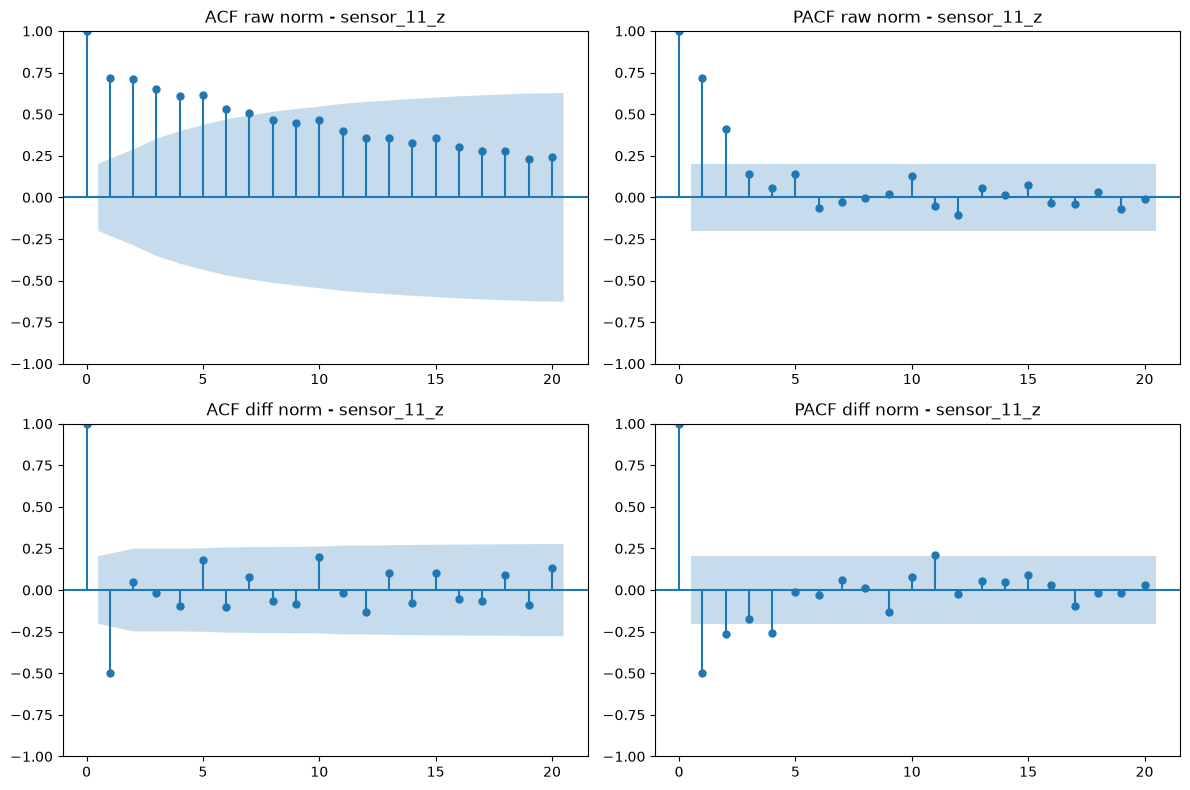

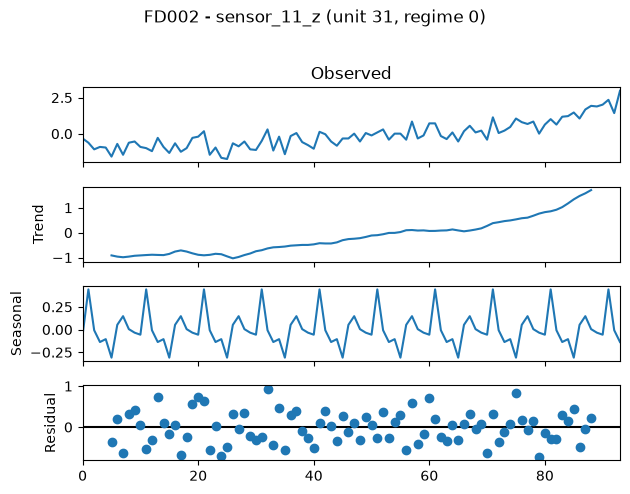

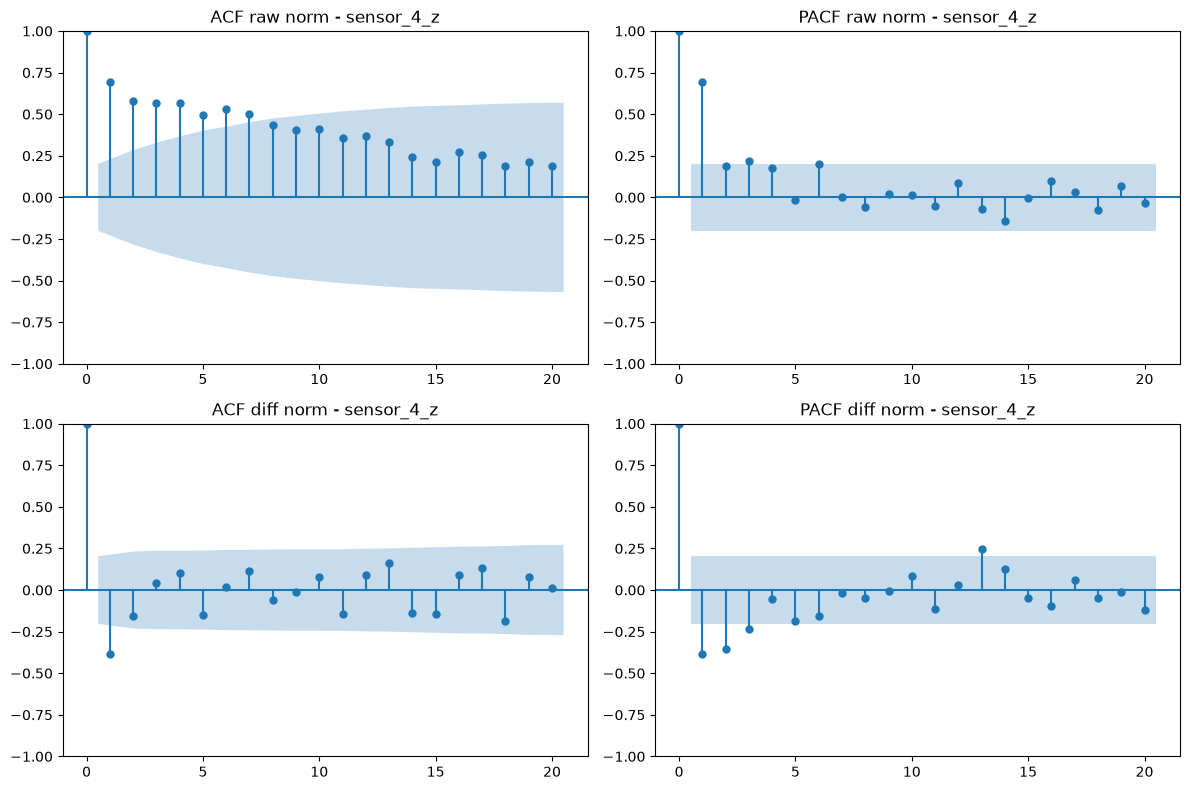

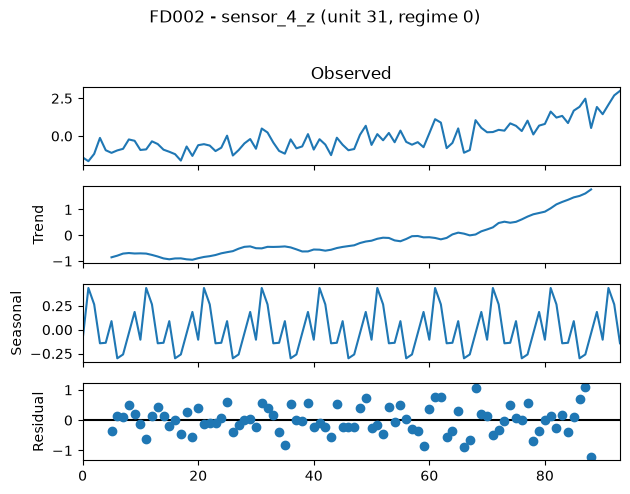

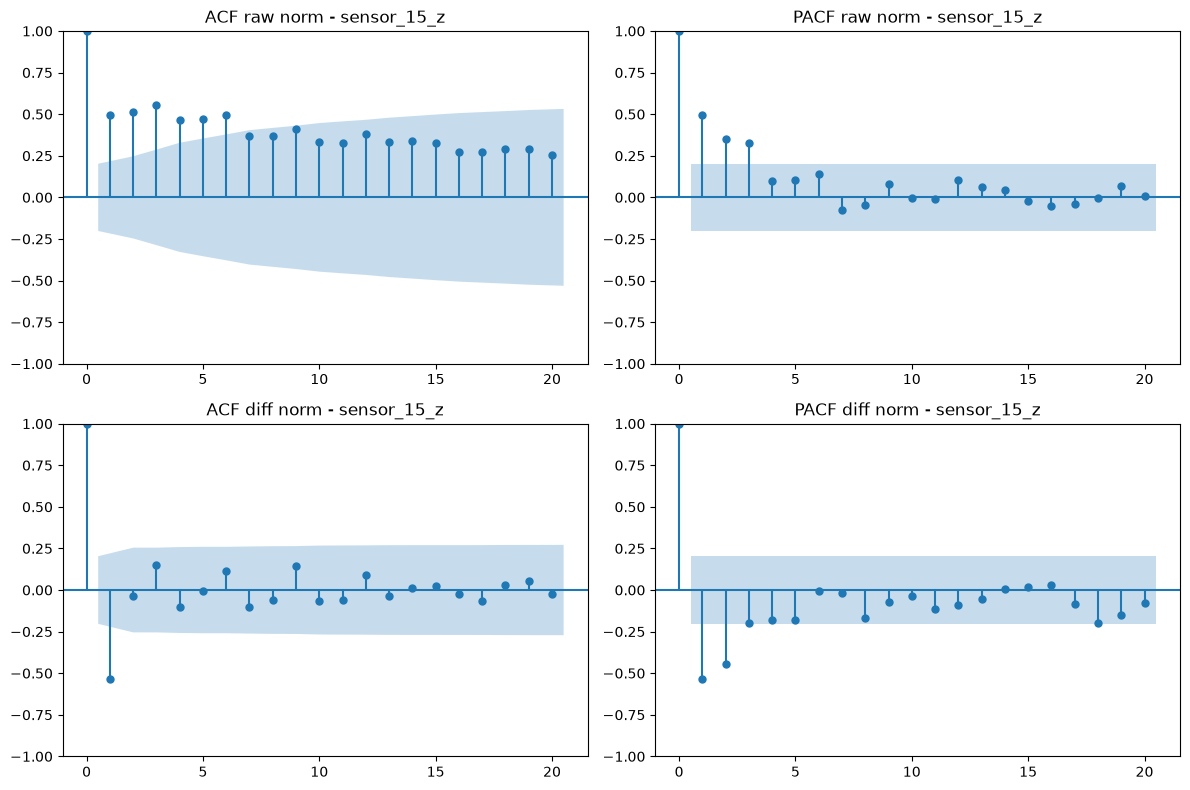

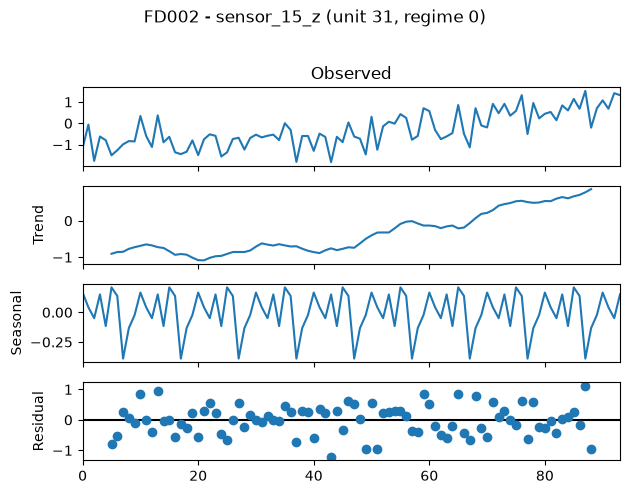

In [40]:
uid = candidate_units[0]
for sensor_z in top3_fd002:
    sub = train2_norm[
        (train2_norm['unit_id'] == uid) &
        (train2_norm['regime'] == main_regime)
    ].sort_values('cycle')
    series = sub[sensor_z].values.astype(float)
    if len(series) < 25:
        continue
    diff = np.diff(series)

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    plot_acf(series, ax=axes[0,0], title=f'ACF raw norm - {sensor_z}')
    plot_pacf(series, ax=axes[0,1], title=f'PACF raw norm - {sensor_z}')
    plot_acf(diff, ax=axes[1,0], title=f'ACF diff norm - {sensor_z}')
    plot_pacf(diff, ax=axes[1,1], title=f'PACF diff norm - {sensor_z}')
    plt.tight_layout(); plt.show()

    seasonal_decompose(series, model='additive', period=10).plot()
    plt.suptitle(f'FD002 - {sensor_z} (unit {uid}, regime {main_regime})',
                 y=1.02)
    plt.tight_layout(); plt.show()